In [1]:
import json
import warnings
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, confusion_matrix, classification_report,
    roc_curve, precision_recall_curve,
)

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

warnings.filterwarnings("ignore")
pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 40)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
TEST_SIZE = 0.2
np.random.seed(RANDOM_STATE)

print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
import sklearn, imblearn
print("scikit-learn:", sklearn.__version__)
print("imblearn    :", imblearn.__version__)

pandas      : 3.0.3
numpy       : 2.4.3
scikit-learn: 1.9.0
imblearn    : 0.14.2


In [2]:
TRANSACTION_TYPES  = ["purchase", "transfer", "withdrawal", "payment", "refund"]
MERCHANT_CATEGORIES = ["grocery", "electronics", "travel", "entertainment",
                       "fuel", "healthcare", "restaurant", "online_services"]
PAYMENT_METHODS    = ["credit_card", "debit_card", "upi", "net_banking", "wallet"]

TYPE_RISK     = {"purchase": 0.0, "payment": 0.1, "refund": 0.5, "withdrawal": 0.9, "transfer": 1.1}
MERCHANT_RISK = {"grocery": -0.4, "restaurant": -0.3, "fuel": -0.1, "healthcare": -0.1,
                 "entertainment": 0.1, "travel": 0.6, "electronics": 0.8, "online_services": 0.9}
METHOD_RISK   = {"debit_card": -0.2, "net_banking": 0.0, "upi": 0.1,
                 "credit_card": 0.4, "wallet": 0.6}


def generate_transactions(n: int = 12_000, seed: int = RANDOM_STATE) -> pd.DataFrame:
    """Generate synthetic transactions whose fraud labels follow a hidden logistic risk model."""
    rng = np.random.default_rng(seed)

    amount            = np.round(rng.lognormal(mean=5.6, sigma=1.15, size=n), 2)
    customer_age      = rng.integers(18, 80, size=n)
    transaction_hour  = rng.integers(0, 24, size=n)
    transaction_type  = rng.choice(TRANSACTION_TYPES, size=n, p=[0.45, 0.15, 0.15, 0.20, 0.05])
    merchant_category = rng.choice(MERCHANT_CATEGORIES, size=n)
    payment_method    = rng.choice(PAYMENT_METHODS, size=n, p=[0.30, 0.25, 0.20, 0.15, 0.10])

    logit = (
        -8.6
        + 1.15 * np.log1p(amount) / 2.2
        + np.array([TYPE_RISK[t] for t in transaction_type])
        + np.array([MERCHANT_RISK[m] for m in merchant_category])
        + np.array([METHOD_RISK[p] for p in payment_method])
        + 1.15 * ((transaction_hour >= 23) | (transaction_hour <= 5))
        + 0.50 * (customer_age < 25)
        + 0.35 * (customer_age > 68)
        + 0.90 * (amount > 8000)
        + rng.normal(0, 0.15, size=n)
    )
    # Standardise then re-scale so the classes separate clearly at a ~3% base rate.
    logit = -6.0 + 2.6 * (logit - logit.mean()) / logit.std()
    prob  = 1 / (1 + np.exp(-logit))
    is_fraud = (rng.random(n) < prob).astype(int)

    df = pd.DataFrame({
        "transaction_id":   [f"TXN{i:06d}" for i in range(1, n + 1)],
        "amount":            amount,
        "transaction_type":  transaction_type,
        "merchant_category": merchant_category,
        "customer_age":      customer_age,
        "payment_method":    payment_method,
        "transaction_hour":  transaction_hour,
        "is_fraud":          is_fraud,
    })

    # Inject realistic messiness so the cleaning step is exercised.
    df.loc[rng.choice(n, size=int(n * 0.01), replace=False), "customer_age"] = np.nan
    df.loc[rng.choice(n, size=int(n * 0.01), replace=False), "merchant_category"] = None
    return df


DATA_PATH = Path("transactions.csv")
if DATA_PATH.exists():
    df_raw = pd.read_csv(DATA_PATH)
    print(f"Loaded existing dataset from {DATA_PATH}")
else:
    df_raw = generate_transactions()
    df_raw.to_csv(DATA_PATH, index=False)
    print(f"Generated new dataset and saved to {DATA_PATH}")

print("Shape:", df_raw.shape)
df_raw.head(10)

Loaded existing dataset from transactions.csv
Shape: (12000, 8)


,transaction_id,amount,transaction_type,merchant_category,customer_age,payment_method,transaction_hour,is_fraud
0,TXN000001,383.92,purchase,grocery,53.0,wallet,12,0
1,TXN000002,81.78,purchase,grocery,35.0,debit_card,9,0
2,TXN000003,640.99,purchase,entertainment,55.0,net_banking,19,0
3,TXN000004,797.63,purchase,entertainment,56.0,debit_card,18,0
4,TXN000005,28.68,withdrawal,restaurant,26.0,net_banking,3,0
5,TXN000006,60.49,payment,entertainment,30.0,net_banking,11,0
6,TXN000007,313.25,purchase,healthcare,36.0,debit_card,9,0
7,TXN000008,187.98,transfer,entertainment,51.0,wallet,10,0
8,TXN000009,265.25,purchase,entertainment,27.0,credit_card,8,0
9,TXN000010,101.39,purchase,healthcare,65.0,net_banking,19,0


In [3]:
print("=== Structure ===")
df_raw.info()

print("\n=== Missing values per column ===")
print(df_raw.isna().sum())

print("\n=== Numeric summary ===")
display(df_raw[["amount", "customer_age", "transaction_hour"]].describe().round(2))

print("=== Target balance ===")
counts = df_raw["is_fraud"].value_counts().sort_index()
print(counts.rename({0: "legitimate", 1: "fraud"}))
print(f"\nFraud rate: {df_raw['is_fraud'].mean():.2%}  "
      f"-> imbalance ratio 1 fraud : {counts[0] / counts[1]:.1f} legitimate")

=== Structure ===
<class 'pandas.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   transaction_id     12000 non-null  str    
 1   amount             12000 non-null  float64
 2   transaction_type   12000 non-null  str    
 3   merchant_category  11880 non-null  str    
 4   customer_age       11880 non-null  float64
 5   payment_method     12000 non-null  str    
 6   transaction_hour   12000 non-null  int64  
 7   is_fraud           12000 non-null  int64  
dtypes: float64(2), int64(2), str(4)
memory usage: 1.1 MB

=== Missing values per column ===
transaction_id         0
amount                 0
transaction_type       0
merchant_category    120
customer_age         120
payment_method         0
transaction_hour       0
is_fraud               0
dtype: int64

=== Numeric summary ===


,amount,customer_age,transaction_hour
count,12000.00,11880.00,12000.00
mean,524.28,48.70,11.49
std,914.63,17.96,6.94
min,1.74,18.00,0.00
25%,123.94,33.00,5.00
50%,265.48,49.00,12.00
75%,571.04,64.00,18.00
max,32013.97,79.00,23.00


=== Target balance ===
is_fraud
legitimate    11587
fraud           413
Name: count, dtype: int64

Fraud rate: 3.44%  -> imbalance ratio 1 fraud : 28.1 legitimate


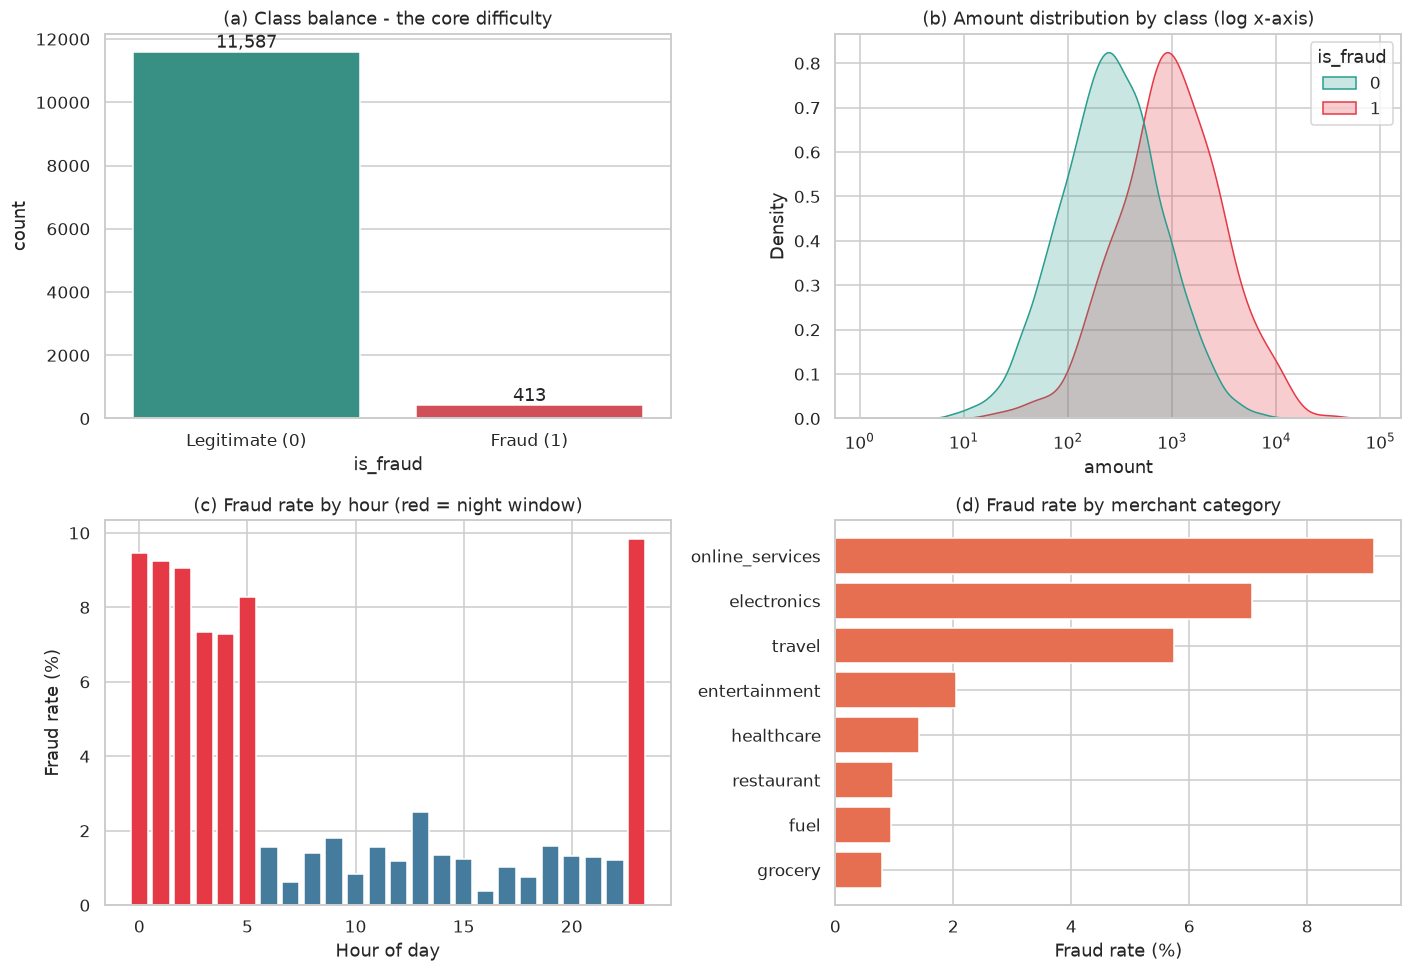

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# (a) Class balance
sns.countplot(x="is_fraud", data=df_raw, ax=axes[0, 0], palette=["#2a9d8f", "#e63946"])
axes[0, 0].set_title("(a) Class balance - the core difficulty")
axes[0, 0].set_xticklabels(["Legitimate (0)", "Fraud (1)"])
for p in axes[0, 0].patches:
    axes[0, 0].annotate(f"{int(p.get_height()):,}", (p.get_x() + p.get_width() / 2, p.get_height()),
                        ha="center", va="bottom")

# (b) Amount distribution by class (log scale)
sns.kdeplot(data=df_raw, x="amount", hue="is_fraud", log_scale=True, fill=True,
            common_norm=False, palette=["#2a9d8f", "#e63946"], ax=axes[0, 1])
axes[0, 1].set_title("(b) Amount distribution by class (log x-axis)")

# (c) Fraud rate by hour
hourly = df_raw.groupby("transaction_hour")["is_fraud"].mean() * 100
colors = ["#e63946" if (h >= 23 or h <= 5) else "#457b9d" for h in hourly.index]
axes[1, 0].bar(hourly.index, hourly.values, color=colors)
axes[1, 0].set_title("(c) Fraud rate by hour (red = night window)")
axes[1, 0].set_xlabel("Hour of day"); axes[1, 0].set_ylabel("Fraud rate (%)")

# (d) Fraud rate by merchant category
cat = (df_raw.groupby("merchant_category")["is_fraud"].mean() * 100).sort_values()
axes[1, 1].barh(cat.index, cat.values, color="#e76f51")
axes[1, 1].set_title("(d) Fraud rate by merchant category")
axes[1, 1].set_xlabel("Fraud rate (%)")

plt.tight_layout(); plt.show()

In [5]:
print("Fraud rate by transaction type:")
print((df_raw.groupby("transaction_type")["is_fraud"].agg(["mean", "count"])
        .assign(fraud_rate_pct=lambda d: (d["mean"] * 100).round(2))
        .drop(columns="mean").sort_values("fraud_rate_pct", ascending=False)))

print("\nFraud rate by payment method:")
print((df_raw.groupby("payment_method")["is_fraud"].agg(["mean", "count"])
        .assign(fraud_rate_pct=lambda d: (d["mean"] * 100).round(2))
        .drop(columns="mean").sort_values("fraud_rate_pct", ascending=False)))

night = df_raw["transaction_hour"].between(23, 23) | (df_raw["transaction_hour"] <= 5)
print(f"\nFraud rate at night  (23:00-05:59): {df_raw.loc[night, 'is_fraud'].mean():.2%}")
print(f"Fraud rate in daytime (06:00-22:59): {df_raw.loc[~night, 'is_fraud'].mean():.2%}")

Fraud rate by transaction type:
                  count  fraud_rate_pct
transaction_type                       
transfer           1821            8.07
withdrawal         1840            6.68
refund              587            3.07
purchase           5352            1.64
payment            2400            1.54

Fraud rate by payment method:
                count  fraud_rate_pct
payment_method                       
wallet           1190            6.30
credit_card      3628            4.52
upi              2435            2.87
net_banking      1729            2.72
debit_card       3018            1.89

Fraud rate at night  (23:00-05:59): 8.67%
Fraud rate in daytime (06:00-22:59): 1.27%


In [6]:
NUMERIC_FEATURES     = ["amount", "customer_age", "transaction_hour"]
CATEGORICAL_FEATURES = ["transaction_type", "merchant_category", "payment_method"]
REQUIRED_COLUMNS     = NUMERIC_FEATURES + CATEGORICAL_FEATURES
TARGET               = "is_fraud"


class DataValidationError(ValueError):
    """Raised when a dataset does not satisfy the expected schema."""


def validate_dataframe(df: pd.DataFrame, require_target: bool = False) -> pd.DataFrame:
    if df is None or df.empty:
        raise DataValidationError("Dataset is empty.")

    missing = [c for c in REQUIRED_COLUMNS if c not in df.columns]
    if missing:
        raise DataValidationError(f"Missing required column(s): {', '.join(missing)}")

    if require_target:
        if TARGET not in df.columns:
            raise DataValidationError(f"Training data must contain the target column '{TARGET}'.")
        labels = set(pd.to_numeric(df[TARGET], errors="coerce").dropna().unique())
        if not labels.issubset({0, 1}):
            raise DataValidationError(f"Target '{TARGET}' must only contain 0 and 1.")
        if len(labels) < 2:
            raise DataValidationError("Training data must contain both fraud and non-fraud rows.")
    return df


validate_dataframe(df_raw, require_target=True)
print("Schema validation passed: all required columns present, target is binary with both classes.")

# Demonstrate that the guard actually fires:
try:
    validate_dataframe(df_raw.drop(columns=["amount"]), require_target=True)
except DataValidationError as exc:
    print("Guard works ->", exc)

Schema validation passed: all required columns present, target is binary with both classes.
Guard works -> Missing required column(s): amount


In [7]:
def clean_dataframe(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()

    for col in NUMERIC_FEATURES:                       # numeric: coerce + median impute
        out[col] = pd.to_numeric(out[col], errors="coerce")
        out[col] = out[col].fillna(out[col].median()) if out[col].notna().any() else 0.0

    for col in CATEGORICAL_FEATURES:                   # categorical: normalise + mode impute
        out[col] = out[col].astype("string").str.strip().str.lower().replace({"": pd.NA})
        mode = out[col].mode(dropna=True)
        out[col] = out[col].fillna(mode.iloc[0] if not mode.empty else "unknown").astype(str)

    out["amount"]           = out["amount"].clip(lower=0)                       # sanity clipping
    out["customer_age"]     = out["customer_age"].clip(lower=15, upper=100)
    out["transaction_hour"] = out["transaction_hour"].clip(0, 23).round().astype(int)

    if TARGET in out.columns:
        out[TARGET] = pd.to_numeric(out[TARGET], errors="coerce").fillna(0).astype(int)
    return out


print("Missing BEFORE cleaning:")
print(df_raw[REQUIRED_COLUMNS].isna().sum().to_string())

df_clean = clean_dataframe(df_raw)

print("\nMissing AFTER cleaning:")
print(df_clean[REQUIRED_COLUMNS].isna().sum().to_string())
print(f"\nRows: {len(df_clean):,} (no rows dropped - imputation preserves every transaction)")
df_clean.head(3)

Missing BEFORE cleaning:
amount                 0
customer_age         120
transaction_hour       0
transaction_type       0
merchant_category    120
payment_method         0

Missing AFTER cleaning:
amount               0
customer_age         0
transaction_hour     0
transaction_type     0
merchant_category    0
payment_method       0

Rows: 12,000 (no rows dropped - imputation preserves every transaction)


,transaction_id,amount,transaction_type,merchant_category,customer_age,payment_method,transaction_hour,is_fraud
0,TXN000001,383.92,purchase,grocery,53.0,wallet,12,0
1,TXN000002,81.78,purchase,grocery,35.0,debit_card,9,0
2,TXN000003,640.99,purchase,entertainment,55.0,net_banking,19,0


In [8]:
HIGH_AMOUNT_THRESHOLD = 5000.0
ENGINEERED_NUMERIC     = ["log_amount", "is_night", "is_high_amount", "amount_per_age"]
ENGINEERED_CATEGORICAL = ["age_band", "amount_band"]


def add_features(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    out["log_amount"]     = np.log1p(out["amount"].astype(float))
    hour                  = out["transaction_hour"].astype(int)
    out["is_night"]       = ((hour >= 23) | (hour <= 5)).astype(int)
    out["is_high_amount"] = (out["amount"].astype(float) >= HIGH_AMOUNT_THRESHOLD).astype(int)
    out["amount_per_age"] = out["amount"].astype(float) / out["customer_age"].clip(lower=1)

    out["age_band"] = pd.cut(out["customer_age"].astype(float),
                             bins=[0, 25, 35, 50, 65, 200],
                             labels=["under25", "25_35", "35_50", "50_65", "65plus"]).astype(str)
    out["amount_band"] = pd.cut(out["amount"].astype(float),
                                bins=[-0.01, 100, 500, 2000, 5000, float("inf")],
                                labels=["micro", "small", "medium", "large", "very_large"]).astype(str)
    return out


df_feat = add_features(df_clean)

MODEL_NUMERIC     = NUMERIC_FEATURES + ENGINEERED_NUMERIC
MODEL_CATEGORICAL = CATEGORICAL_FEATURES + ENGINEERED_CATEGORICAL

print(f"Columns before engineering: {df_clean.shape[1]}  ->  after: {df_feat.shape[1]}")
print(f"Numeric features fed to the model     ({len(MODEL_NUMERIC)}): {MODEL_NUMERIC}")
print(f"Categorical features fed to the model ({len(MODEL_CATEGORICAL)}): {MODEL_CATEGORICAL}")
df_feat[["amount", "log_amount", "transaction_hour", "is_night",
         "is_high_amount", "amount_per_age", "age_band", "amount_band"]].head()

Columns before engineering: 8  ->  after: 14
Numeric features fed to the model     (7): ['amount', 'customer_age', 'transaction_hour', 'log_amount', 'is_night', 'is_high_amount', 'amount_per_age']
Categorical features fed to the model (5): ['transaction_type', 'merchant_category', 'payment_method', 'age_band', 'amount_band']


,amount,log_amount,transaction_hour,is_night,is_high_amount,amount_per_age,age_band,amount_band
0,383.92,5.953036,12,0,0,7.243774,50_65,small
1,81.78,4.416186,9,0,0,2.336571,25_35,micro
2,640.99,6.464573,19,0,0,11.654364,50_65,medium
3,797.63,6.682898,18,0,0,14.243393,50_65,medium
4,28.68,3.390473,3,1,0,1.103077,25_35,micro


In [9]:
# Sanity check: do the engineered flags actually separate the classes?
check = pd.DataFrame({
    "is_night":       df_feat.groupby("is_night")["is_fraud"].mean() * 100,
    })
print("Fraud rate (%) by is_night:")
print((df_feat.groupby("is_night")["is_fraud"].mean() * 100).round(2).to_string())
print("\nFraud rate (%) by is_high_amount:")
print((df_feat.groupby("is_high_amount")["is_fraud"].mean() * 100).round(2).to_string())
print("\nFraud rate (%) by amount_band:")
print((df_feat.groupby("amount_band")["is_fraud"].mean() * 100).round(2).to_string())
print("\nFraud rate (%) by age_band:")
print((df_feat.groupby("age_band")["is_fraud"].mean() * 100).round(2).to_string())

Fraud rate (%) by is_night:
is_night
0    1.27
1    8.67

Fraud rate (%) by is_high_amount:
is_high_amount
0     3.19
1    42.67

Fraud rate (%) by amount_band:
amount_band
large         17.61
medium         6.49
micro          0.38
small          1.67
very_large    42.67

Fraud rate (%) by age_band:
age_band
25_35      3.05
35_50      2.70
50_65      2.77
65plus     3.98
under25    5.69


In [10]:
y = df_feat[TARGET]
X = df_feat.drop(columns=[TARGET])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)

split_summary = pd.DataFrame({
    "rows":        [len(X_train), len(X_test)],
    "fraud":       [int(y_train.sum()), int(y_test.sum())],
    "legitimate":  [int((y_train == 0).sum()), int((y_test == 0).sum())],
    "fraud_rate":  [f"{y_train.mean():.2%}", f"{y_test.mean():.2%}"],
}, index=["train", "test"])
display(split_summary)
print("Fraud rate is preserved in both partitions -> stratification worked.")

,rows,fraud,legitimate,fraud_rate
train,9600,330,9270,3.44%
test,2400,83,2317,3.46%


Fraud rate is preserved in both partitions -> stratification worked.


In [11]:
encoder = ColumnTransformer(
    transformers=[
        ("num", "passthrough", MODEL_NUMERIC),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), MODEL_CATEGORICAL),
    ],
    remainder="drop",                       # transaction_id and other columns are dropped
    verbose_feature_names_out=False,
)

_preview = encoder.fit_transform(X_train)
print(f"Encoded matrix shape: {_preview.shape}  ({len(MODEL_NUMERIC)} numeric + "
      f"{_preview.shape[1] - len(MODEL_NUMERIC)} one-hot columns)")
print("\nFirst 20 encoded feature names:")
print(list(encoder.get_feature_names_out())[:20])

Encoded matrix shape: (9600, 35)  (7 numeric + 28 one-hot columns)

First 20 encoded feature names:
['amount', 'customer_age', 'transaction_hour', 'log_amount', 'is_night', 'is_high_amount', 'amount_per_age', 'transaction_type_payment', 'transaction_type_purchase', 'transaction_type_refund', 'transaction_type_transfer', 'transaction_type_withdrawal', 'merchant_category_electronics', 'merchant_category_entertainment', 'merchant_category_fuel', 'merchant_category_grocery', 'merchant_category_healthcare', 'merchant_category_online_services', 'merchant_category_restaurant', 'merchant_category_travel']


In [12]:
# Illustration only: what SMOTE does to the TRAINING data (the pipeline does this internally).
_X_enc = encoder.fit_transform(X_train)
_X_res, _y_res = SMOTE(random_state=RANDOM_STATE, k_neighbors=5).fit_resample(_X_enc, y_train)

before = pd.Series(y_train).value_counts().sort_index()
after  = pd.Series(_y_res).value_counts().sort_index()
comparison = pd.DataFrame({"before SMOTE": before, "after SMOTE": after}) \
               .rename(index={0: "legitimate", 1: "fraud"})
display(comparison)
print(f"Training rows: {len(y_train):,} -> {len(_y_res):,}   "
      f"({after[1] - before[1]:,} synthetic fraud samples created)")
print("The TEST set is untouched and keeps its original real-world fraud rate.")

,before SMOTE,after SMOTE
is_fraud,,
legitimate,9270,9270
fraud,330,9270


Training rows: 9,600 -> 18,540   (8,940 synthetic fraud samples created)
The TEST set is untouched and keeps its original real-world fraud rate.


In [13]:
pipeline = ImbPipeline(steps=[
    ("encode", encoder),                                                  # Step 5
    ("smote",  SMOTE(random_state=RANDOM_STATE, k_neighbors=5)),          # Step 6 (fit only)
    ("scale",  StandardScaler()),                                         # Step 7
    ("clf",    LogisticRegression(C=1.0, max_iter=1000, solver="lbfgs",   # Step 8
                                  random_state=RANDOM_STATE)),
])
pipeline

,steps,"[('encode', ...), ('smote', ...), ...]"
,transform_input,None
,memory,None
,verbose,False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weigh

In [14]:
%time pipeline.fit(X_train, y_train)

n_features = len(pipeline.named_steps["encode"].get_feature_names_out())
print(f"\nTraining complete.")
print(f"Features after encoding : {n_features}")
print(f"Intercept               : {pipeline.named_steps['clf'].intercept_[0]:.4f}")
print(f"Converged in            : {pipeline.named_steps['clf'].n_iter_[0]} iterations")

CPU times: user 8.47 s, sys: 20 ms, total: 8.49 s
Wall time: 626 ms

Training complete.
Features after encoding : 35
Intercept               : -0.4657
Converged in            : 20 iterations


In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_auc    = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="roc_auc")
cv_recall = cross_val_score(pipeline, X_train, y_train, cv=cv, scoring="recall")

print("5-fold CV ROC-AUC per fold:", np.round(cv_auc, 4))
print(f"  mean = {cv_auc.mean():.4f}  (std = {cv_auc.std():.4f})")
print("\n5-fold CV recall per fold :", np.round(cv_recall, 4))
print(f"  mean = {cv_recall.mean():.4f}  (std = {cv_recall.std():.4f})")
print("\nLow standard deviation -> the model is stable, not a lucky split.")

5-fold CV ROC-AUC per fold: [0.9574 0.9384 0.9191 0.9551 0.9485]
  mean = 0.9437  (std = 0.0140)

5-fold CV recall per fold : [0.8788 0.8333 0.7727 0.8788 0.8788]
  mean = 0.8485  (std = 0.0418)

Low standard deviation -> the model is stable, not a lucky split.


In [16]:
y_pred  = pipeline.predict(X_test)
y_proba = pipeline.predict_proba(X_test)[:, 1]

metrics = {
    "accuracy":  accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall":    recall_score(y_test, y_pred, zero_division=0),
    "f1":        f1_score(y_test, y_pred, zero_division=0),
    "roc_auc":   roc_auc_score(y_test, y_proba),
    "pr_auc":    average_precision_score(y_test, y_proba),
}

display(pd.DataFrame({"score": metrics}).round(4))

print("Classification report:")
print(classification_report(y_test, y_pred, target_names=["Legitimate", "Fraud"], digits=4))

baseline = (y_test == 0).mean()
print(f"Trivial 'always legitimate' baseline accuracy: {baseline:.4f} with recall 0.0000")
print("-> accuracy alone would make a useless model look excellent.")

,score
accuracy,0.8758
precision,0.1989
recall,0.8554
f1,0.3227
roc_auc,0.9358
pr_auc,0.4488


Classification report:
              precision    recall  f1-score   support

  Legitimate     0.9941    0.8766    0.9317      2317
       Fraud     0.1989    0.8554    0.3227        83

    accuracy                         0.8758      2400
   macro avg     0.5965    0.8660    0.6272      2400
weighted avg     0.9666    0.8758    0.9106      2400

Trivial 'always legitimate' baseline accuracy: 0.9654 with recall 0.0000
-> accuracy alone would make a useless model look excellent.


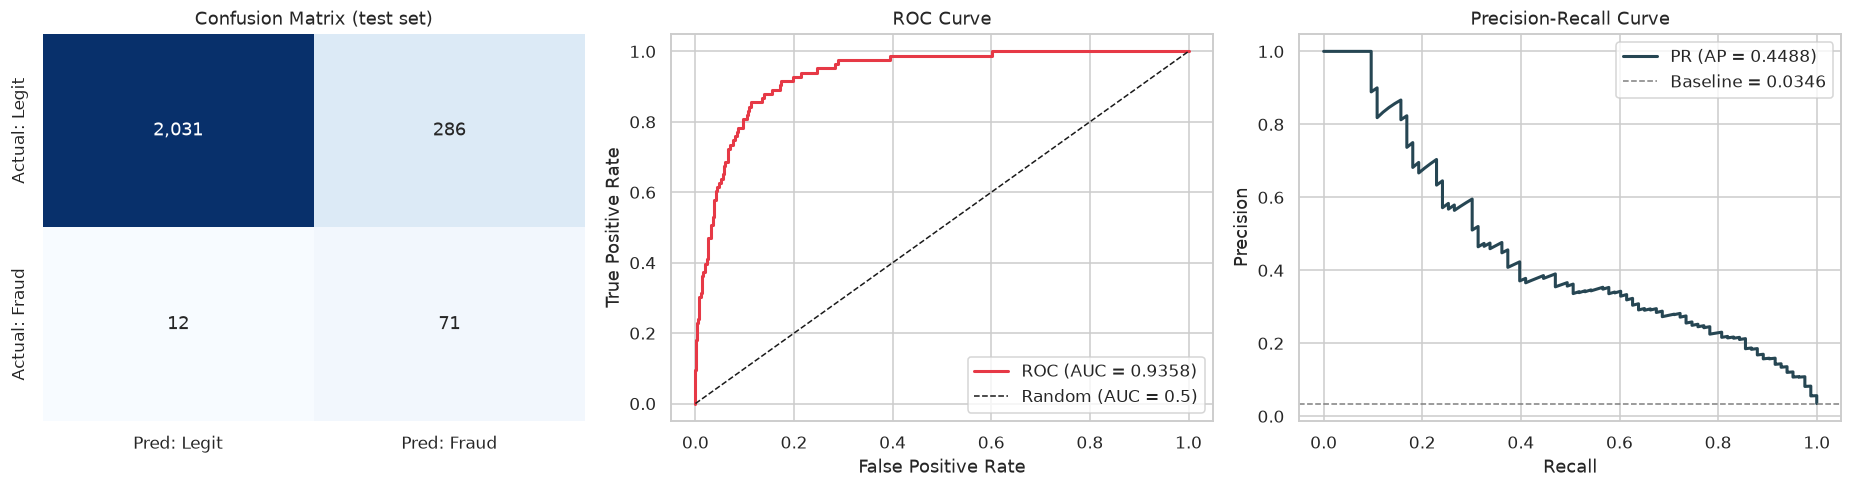

True Negatives : 2,031   (legitimate, correctly cleared)
False Positives: 286   (legitimate, sent for review)
False Negatives: 12   (fraud, MISSED - the costly error)
True Positives : 71   (fraud, caught)


In [17]:
cm = confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

fig, axes = plt.subplots(1, 3, figsize=(17, 4.6))

sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=["Pred: Legit", "Pred: Fraud"],
            yticklabels=["Actual: Legit", "Actual: Fraud"])
axes[0].set_title("Confusion Matrix (test set)")

fpr, tpr, _ = roc_curve(y_test, y_proba)
axes[1].plot(fpr, tpr, color="#e63946", lw=2, label=f"ROC (AUC = {metrics['roc_auc']:.4f})")
axes[1].plot([0, 1], [0, 1], "k--", lw=1, label="Random (AUC = 0.5)")
axes[1].set_xlabel("False Positive Rate"); axes[1].set_ylabel("True Positive Rate")
axes[1].set_title("ROC Curve"); axes[1].legend(loc="lower right")

prec, rec, _ = precision_recall_curve(y_test, y_proba)
axes[2].plot(rec, prec, color="#264653", lw=2, label=f"PR (AP = {metrics['pr_auc']:.4f})")
axes[2].axhline(y_test.mean(), ls="--", c="grey", lw=1,
                label=f"Baseline = {y_test.mean():.4f}")
axes[2].set_xlabel("Recall"); axes[2].set_ylabel("Precision")
axes[2].set_title("Precision-Recall Curve"); axes[2].legend()

plt.tight_layout(); plt.show()

print(f"True Negatives : {tn:,}   (legitimate, correctly cleared)")
print(f"False Positives: {fp:,}   (legitimate, sent for review)")
print(f"False Negatives: {fn:,}   (fraud, MISSED - the costly error)")
print(f"True Positives : {tp:,}   (fraud, caught)")

,feature,coefficient,effect
0,log_amount,1.7247,Increases fraud risk
1,is_night,1.6665,Increases fraud risk
2,merchant_category_online_services,0.6398,Increases fraud risk
3,transaction_type_transfer,0.5976,Increases fraud risk
4,amount,0.5847,Increases fraud risk
5,merchant_category_grocery,-0.5595,Reduces fraud risk
6,transaction_type_withdrawal,0.5406,Increases fraud risk
7,transaction_type_purchase,-0.5379,Reduces fraud risk
8,merchant_category_electronics,0.5339,Increases fraud risk
9,merchant_category_fuel,-0.5272,Reduces fraud risk


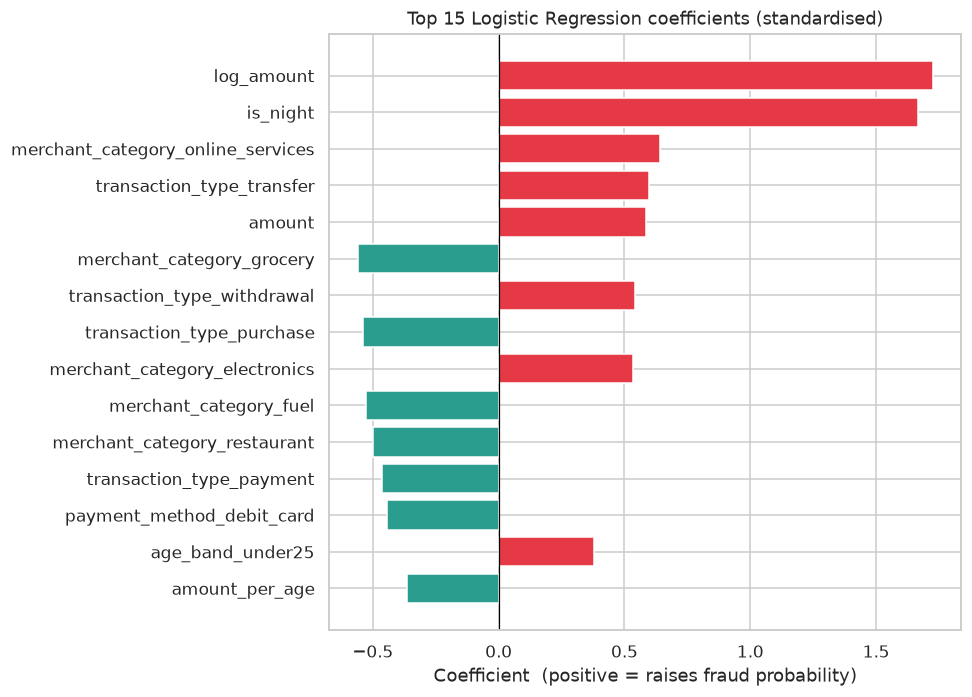

In [18]:
feature_names = pipeline.named_steps["encode"].get_feature_names_out()
coefs = pipeline.named_steps["clf"].coef_[0]

importance = (pd.DataFrame({"feature": feature_names, "coefficient": coefs})
                .assign(abs_coef=lambda d: d["coefficient"].abs(),
                        effect=lambda d: np.where(d["coefficient"] > 0,
                                                  "Increases fraud risk", "Reduces fraud risk"))
                .sort_values("abs_coef", ascending=False)
                .reset_index(drop=True))

display(importance.head(15)[["feature", "coefficient", "effect"]].round(4))

top = importance.head(15).iloc[::-1]
plt.figure(figsize=(9, 6.5))
plt.barh(top["feature"], top["coefficient"],
         color=np.where(top["coefficient"] > 0, "#e63946", "#2a9d8f"))
plt.axvline(0, color="black", lw=0.8)
plt.title("Top 15 Logistic Regression coefficients (standardised)")
plt.xlabel("Coefficient  (positive = raises fraud probability)")
plt.tight_layout(); plt.show()

In [19]:
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]:
    pred_t = (y_proba >= t).astype(int)
    tn_t, fp_t, fn_t, tp_t = confusion_matrix(y_test, pred_t).ravel()
    rows.append({
        "threshold":  t,
        "precision":  round(precision_score(y_test, pred_t, zero_division=0), 4),
        "recall":     round(recall_score(y_test, pred_t, zero_division=0), 4),
        "f1":         round(f1_score(y_test, pred_t, zero_division=0), 4),
        "frauds_caught": tp_t,
        "frauds_missed": fn_t,
        "false_alarms":  fp_t,
    })
display(pd.DataFrame(rows).set_index("threshold"))
print("Raising the threshold shrinks the manual review queue at the cost of missing more frauds.")

,precision,recall,f1,frauds_caught,frauds_missed,false_alarms
threshold,,,,,,
0.3,0.1532,0.9157,0.2625,76,7,420
0.4,0.1776,0.8795,0.2955,73,10,338
0.5,0.1989,0.8554,0.3227,71,12,286
0.6,0.2287,0.8072,0.3564,67,16,226
0.7,0.2711,0.7349,0.3961,61,22,164
0.8,0.3210,0.6265,0.4245,52,31,110
0.9,0.3900,0.4699,0.4262,39,44,61


Raising the threshold shrinks the manual review queue at the cost of missing more frauds.


In [20]:
MODEL_PATH   = Path("fraud_model.pkl")
METRICS_PATH = Path("metrics.json")

joblib.dump(pipeline, MODEL_PATH)
METRICS_PATH.write_text(json.dumps(
    {**{k: round(float(v), 4) for k, v in metrics.items()},
     "rows": int(len(df_feat)), "train_rows": int(len(X_train)), "test_rows": int(len(X_test)),
     "fraud_rows": int(y.sum()), "fraud_rate": round(float(y.mean()), 4),
     "cv_roc_auc_mean": round(float(cv_auc.mean()), 4),
     "top_features": importance.head(10)[["feature", "coefficient"]].to_dict("records")},
    indent=2))

print(f"Saved model   -> {MODEL_PATH}  ({MODEL_PATH.stat().st_size / 1024:.1f} KB)")
print(f"Saved metrics -> {METRICS_PATH}")

Saved model   -> fraud_model.pkl  (96.7 KB)
Saved metrics -> metrics.json


In [21]:
def predict_transaction(model, txn: dict) -> dict:
    """Score a single raw transaction dict, exactly as the API endpoint would."""
    frame = add_features(clean_dataframe(validate_dataframe(pd.DataFrame([txn]))))
    proba = float(model.predict_proba(frame)[0, 1])
    risk  = "HIGH" if proba >= 0.7 else "MEDIUM" if proba >= 0.4 else "LOW"
    return {"fraud_probability": round(proba, 4),
            "prediction": "FRAUD" if proba >= 0.5 else "LEGITIMATE",
            "risk_level": risk}


loaded = joblib.load(MODEL_PATH)          # prove the artefact round-trips

samples = [
    {"label": "Small daytime grocery purchase (debit card)",
     "txn": {"amount": 240.50, "transaction_type": "purchase", "merchant_category": "grocery",
             "customer_age": 41, "payment_method": "debit_card", "transaction_hour": 13}},
    {"label": "Large 3 a.m. wallet transfer to online services (young customer)",
     "txn": {"amount": 18500.00, "transaction_type": "transfer", "merchant_category": "online_services",
             "customer_age": 21, "payment_method": "wallet", "transaction_hour": 3}},
    {"label": "Mid-size evening electronics purchase (credit card)",
     "txn": {"amount": 4200.00, "transaction_type": "purchase", "merchant_category": "electronics",
             "customer_age": 33, "payment_method": "credit_card", "transaction_hour": 20}},
]

for s in samples:
    out = predict_transaction(loaded, s["txn"])
    print(f"{s['label']}\n   -> probability={out['fraud_probability']:.4f}  "
          f"prediction={out['prediction']}  risk={out['risk_level']}\n")

Small daytime grocery purchase (debit card)
   -> probability=0.0002  prediction=LEGITIMATE  risk=LOW

Large 3 a.m. wallet transfer to online services (young customer)
   -> probability=1.0000  prediction=FRAUD  risk=HIGH

Mid-size evening electronics purchase (credit card)
   -> probability=0.7990  prediction=FRAUD  risk=HIGH



In [22]:
batch = X_test.head(10).copy()
batch_proba = loaded.predict_proba(batch)[:, 1]

batch_out = batch[["amount", "transaction_type", "merchant_category",
                   "payment_method", "customer_age", "transaction_hour"]].copy()
batch_out["fraud_probability"] = batch_proba.round(4)
batch_out["prediction"]        = np.where(batch_proba >= 0.5, "FRAUD", "LEGITIMATE")
batch_out["actual"]            = np.where(y_test.head(10).values == 1, "FRAUD", "LEGITIMATE")
display(batch_out.reset_index(drop=True))

,amount,transaction_type,merchant_category,payment_method,customer_age,transaction_hour,fraud_probability,prediction,actual
0,232.92,withdrawal,online_services,upi,50.0,14,0.1576,LEGITIMATE,LEGITIMATE
1,270.00,transfer,healthcare,debit_card,76.0,9,0.0484,LEGITIMATE,LEGITIMATE
2,447.93,purchase,travel,upi,21.0,23,0.7190,FRAUD,LEGITIMATE
3,237.38,withdrawal,grocery,debit_card,34.0,20,0.0028,LEGITIMATE,LEGITIMATE
4,146.05,purchase,healthcare,net_banking,74.0,22,0.0037,LEGITIMATE,LEGITIMATE
5,287.49,payment,travel,credit_card,60.0,10,0.0209,LEGITIMATE,LEGITIMATE
6,1276.29,payment,restaurant,upi,68.0,11,0.0076,LEGITIMATE,LEGITIMATE
7,97.43,purchase,fuel,net_banking,51.0,12,0.0002,LEGITIMATE,LEGITIMATE
8,37.13,purchase,travel,credit_card,78.0,17,0.0055,LEGITIMATE,LEGITIMATE
9,304.11,purchase,restaurant,wallet,71.0,0,0.2168,LEGITIMATE,LEGITIMATE


In [23]:
summary = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (fraud)", "Recall (fraud)", "F1-score (fraud)",
               "ROC-AUC", "PR-AUC (avg precision)", "CV ROC-AUC (5-fold mean)"],
    "Score":  [metrics["accuracy"], metrics["precision"], metrics["recall"], metrics["f1"],
               metrics["roc_auc"], metrics["pr_auc"], cv_auc.mean()],
    "Interpretation": [
        "Share of all transactions classified correctly.",
        "Of the transactions flagged as fraud, this fraction really were fraud.",
        "Of all actual frauds, this fraction was successfully caught.",
        "Harmonic mean of precision and recall.",
        "Probability the model ranks a random fraud above a random legitimate transaction.",
        "Area under the precision-recall curve - the honest metric under imbalance.",
        "Mean ROC-AUC across 5 stratified folds - stability check.",
    ],
})
summary["Score"] = summary["Score"].round(4)
display(summary.style.hide(axis="index"))

print(f"Test set        : {len(y_test):,} transactions, {int(y_test.sum())} genuine frauds")
print(f"Frauds caught   : {tp} of {int(y_test.sum())}  ({tp / y_test.sum():.2%} recall)")
print(f"Frauds missed   : {fn}")
print(f"False alarms    : {fp} out of {int((y_test == 0).sum()):,} legitimate transactions "
      f"({fp / (y_test == 0).sum():.2%})")

Metric,Score,Interpretation
Accuracy,0.875800,Share of all transactions classified correctly.
Precision (fraud),0.198900,"Of the transactions flagged as fraud, this fraction really were fraud."
Recall (fraud),0.855400,"Of all actual frauds, this fraction was successfully caught."
F1-score (fraud),0.322700,Harmonic mean of precision and recall.
ROC-AUC,0.935800,Probability the model ranks a random fraud above a random legitimate transaction.
PR-AUC (avg precision),0.448800,Area under the precision-recall curve - the honest metric under imbalance.
CV ROC-AUC (5-fold mean),0.943700,Mean ROC-AUC across 5 stratified folds - stability check.


Test set        : 2,400 transactions, 83 genuine frauds
Frauds caught   : 71 of 83  (85.54% recall)
Frauds missed   : 12
False alarms    : 286 out of 2,317 legitimate transactions (12.34%)
